# Fire Identification: A Satellite Data Analysis of the 2019–2020 Fire Season in Australia

**Team:** Ryujin Bupp · Fernando Ricaurte · Hardik Polamarasetti

**Program:** M.S. in Data Analytics, University of Central Florida

**Data:** NASA FIRMS MODIS active-fire detections for Australia, via the Kaggle dataset [*Fires from Space: Australia and New Zealand*](https://www.kaggle.com/datasets/carlosparadis/fires-from-space-australia-and-new-zeland) (file `fire_nrt_M6_96619.csv`, 183,593 detections)

**Question:** Can satellite measurements (brightness, fire radiative power, brightness temperature, scan geometry, acquisition time, location and platform) predict whether a detection is a high-confidence fire?

**Notebook contents**
1. Preprocessing: missing-value check, one-hot encoding, removing a collinear feature, scaling, and a 60/20/20 train/validation/test split
2. Baseline models: logistic regression (high vs. low confidence) and linear regression (confidence %), with exhaustive feature selection
3. Dimension reduction: PCA followed by logistic regression
4. Clustering: K-Means on PCA components
5. Lasso and Ridge via elastic net regression
6. GLMs with appropriate target distributions (Binomial and Gaussian)


In [ ]:
!pip install great_tables

In [ ]:
# Import in all necessary libraries and packages
import warnings
import sys
import math
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as matplt
import seaborn as sea
import statsmodels.api as sm
import scipy.stats as stats
from sklearn import datasets as skldatasets
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import log_loss, confusion_matrix, accuracy_score as accuracy_score, classification_report, mean_squared_error, ConfusionMatrixDisplay, roc_curve, auc, roc_auc_score, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from mlxtend.feature_selection import ExhaustiveFeatureSelector
from tabulate import tabulate
from rich.table import Table
from rich.console import Console
from rich.text import Text
import time
from great_tables import GT
from IPython.display import display, HTML
import warnings
warnings.filterwarnings('ignore')


<h3>Load The Dataset</h3>

In [ ]:
# Load in the fire data into a dataframe
fire_data = pd.read_csv('fire_nrt_M6_96619.csv')

<h3>Preprocessing</h3>

In [ ]:
# Check missing for each column in the training data
missing_fire_data_count = fire_data.isnull().sum()

# Calculate the percentage of missing data for each column and round to 2 decimal places
missing_fire_data_percent = round((missing_fire_data_count/len(fire_data)) * 100,2)

# Add the missing percent data to the dataframe
missing_fire_data_all = pd.concat([missing_fire_data_count, missing_fire_data_percent], axis=1).reset_index()

# Set column names
missing_fire_data_all.columns = ['Column Name', 'Missing Count', 'Missing Percent']

# Only show information for columns missing data
missing_fire_data = (missing_fire_data_all[missing_fire_data_all['Missing Count'] > 0])

# Print title
display(HTML("<h3>Missingness Report</h3>"))

# Print table
missing_fire_data

,Column Name,Missing Count,Missing Percent


In [ ]:
# Check for columns that have only one value
only_one_value = fire_data.nunique(dropna=True) == 1

# Print title
print("\033[1m   Columns That Have Only One Value\033[0m")

# Print the list of columns that have only one value
print(only_one_value[only_one_value])

   Columns That Have Only One Value
instrument    True
version       True
dtype: bool


In [ ]:
# Drop all columns found to only have one value
features_to_drop = only_one_value[only_one_value].index
fire_data.drop(columns=features_to_drop, inplace=True)

# Drop the unique identifyer column
fire_data = fire_data.drop(columns=['acq_date'])

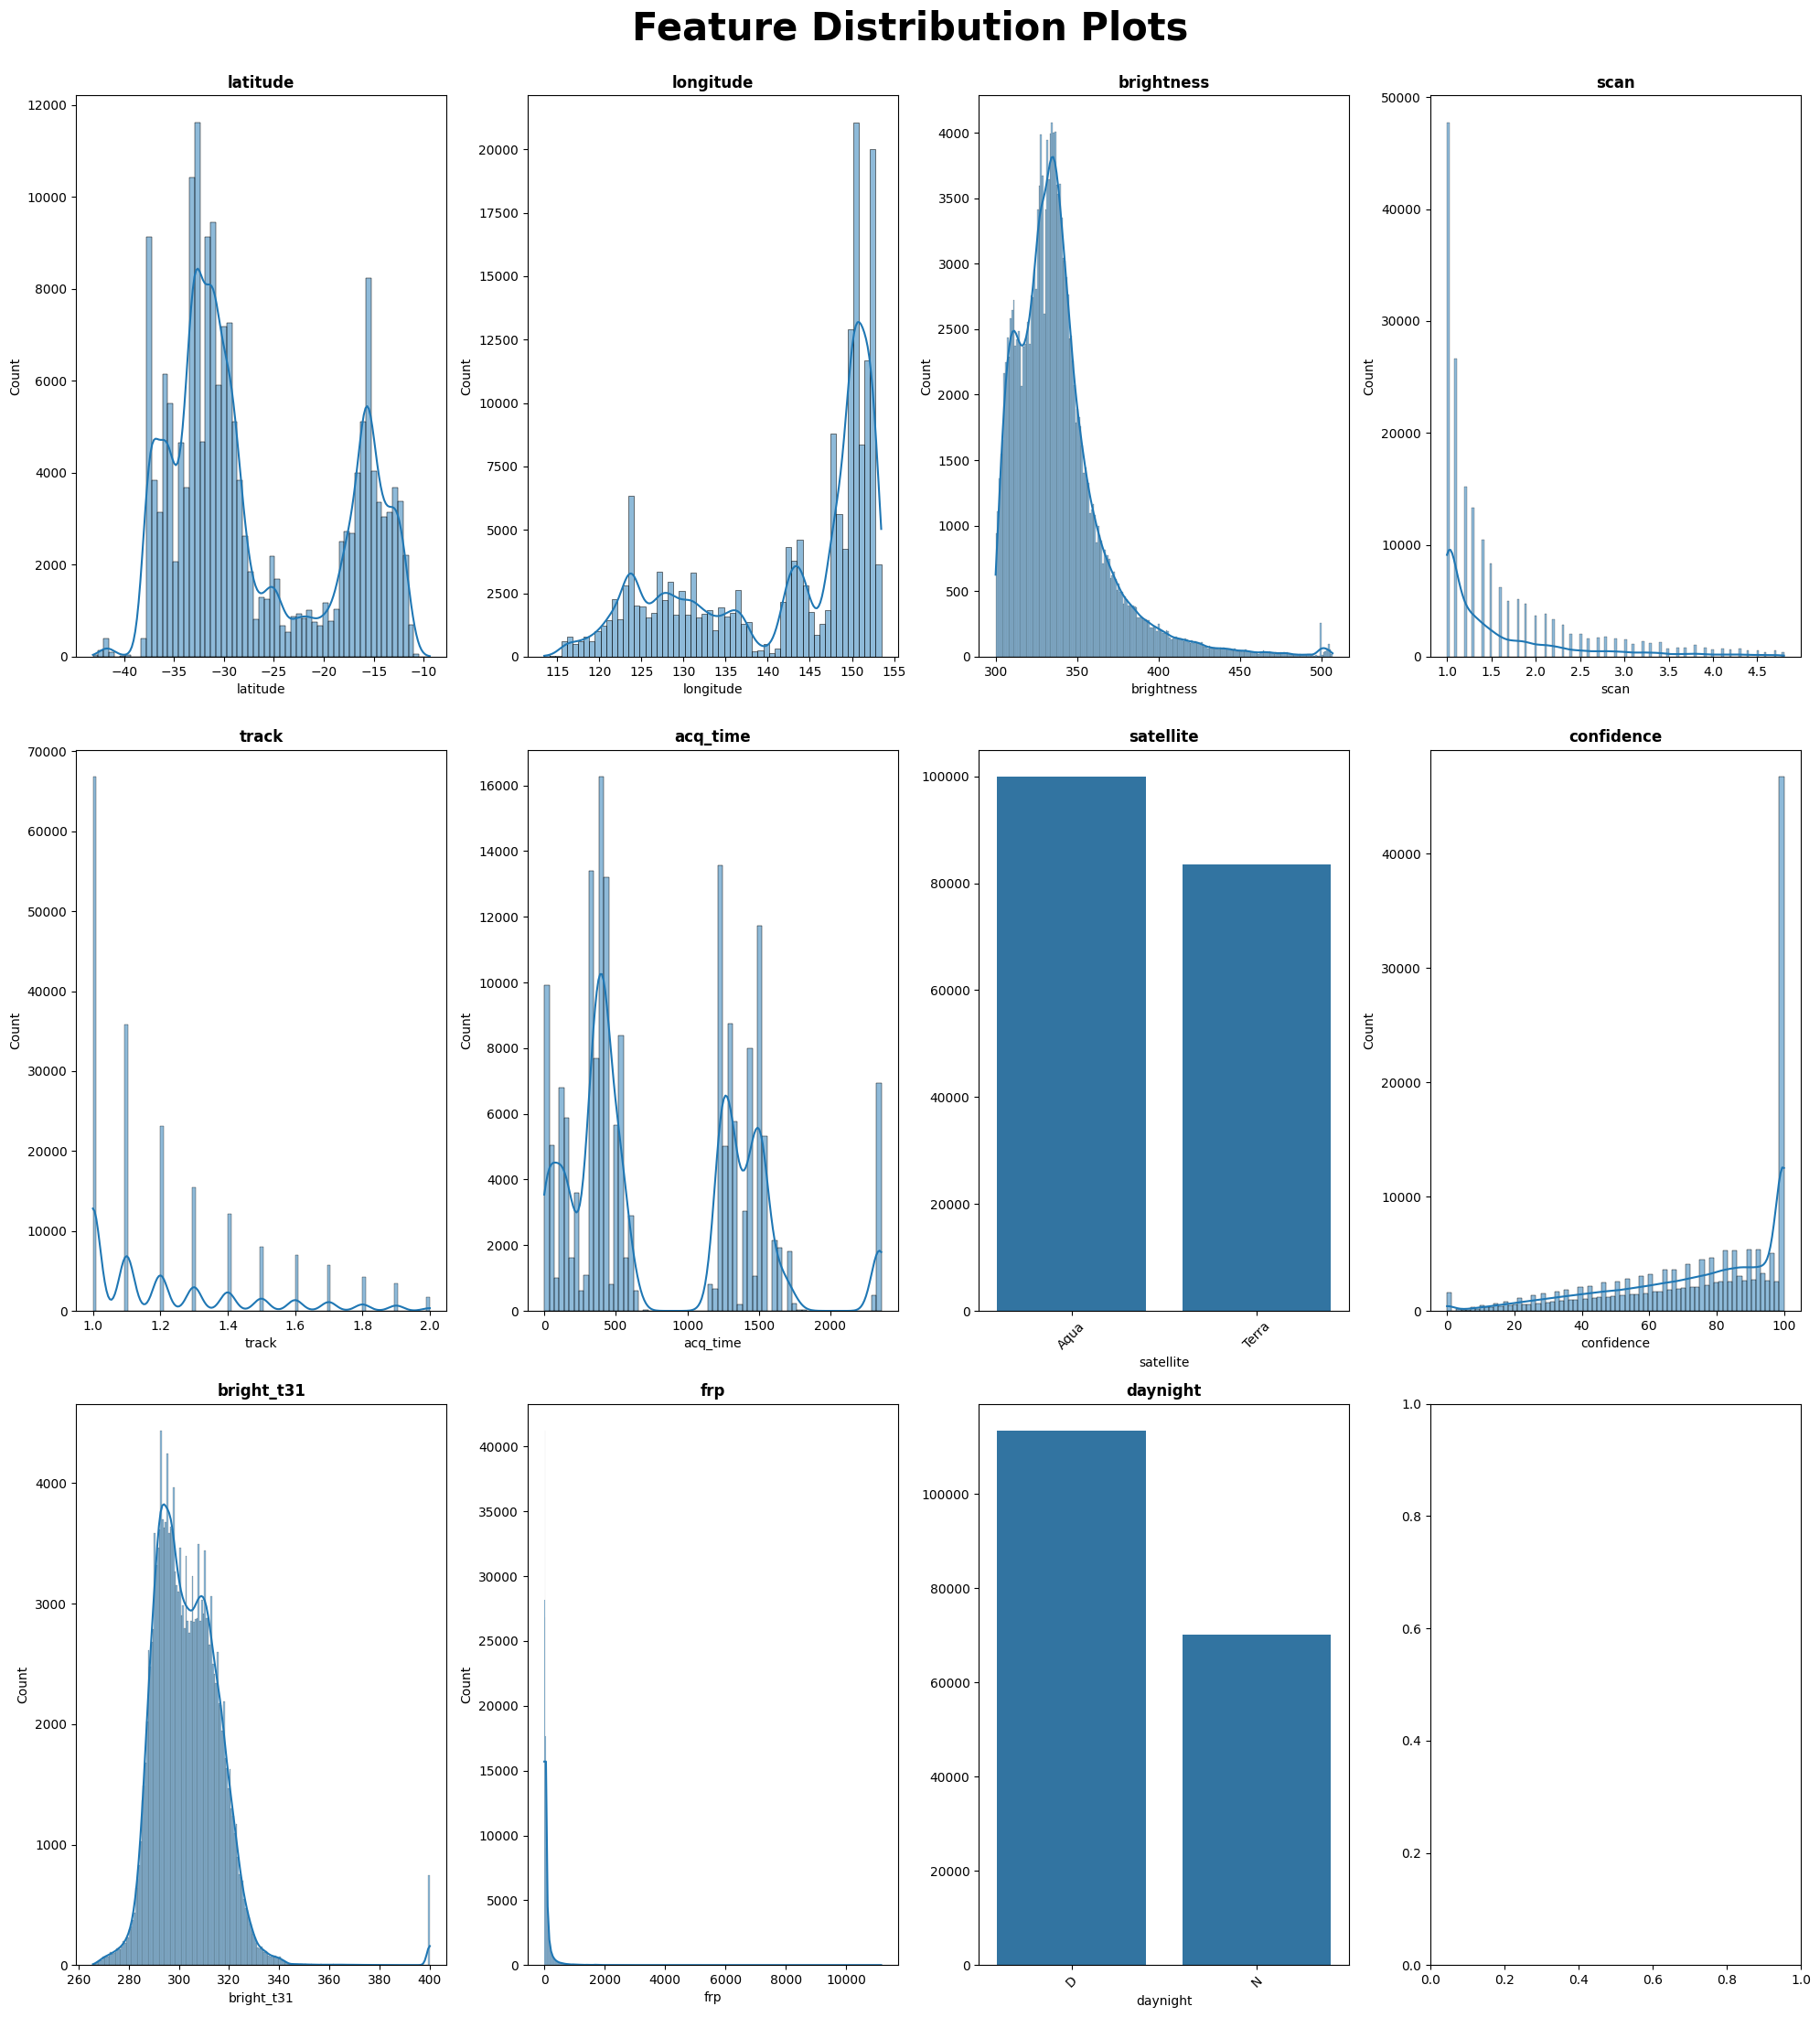

In [ ]:
# Get the column count from the original dataset
col_fire_data = fire_data.columns

# Calculate total number of plots needed
num_plots_fire_data = len(col_fire_data)

# Set how the subplots of each feature will appear by doing some calculations on the rows and colums from the dataset
figure_size_fire_data, figure_axes_fire_data = matplt.subplots(

    # Calculate number of rows necessary
    nrows=(num_plots_fire_data + 3) // 4,

    #specify 4 plots per row
    ncols=4,

    # Calculate appropriate figure size
    figsize=(20, num_plots_fire_data * 2)
)

# Flatten the 2D grid of axes into a 1D list so we can loop through them easily
figure_axes_fire_data = figure_axes_fire_data.flatten()

# Make and position plots title
matplt.suptitle("Feature Distribution Plots", fontweight='bold', fontsize=30, y=1)

# Loop through the dataset columns and create a frequency vs range histogram for each feature
for i, columns_fire_data in enumerate(col_fire_data):

    # Check if data is of a numeric type and if so then proceed to create the histogram
    if fire_data[columns_fire_data].dtype.kind in 'iufc':
        sea.histplot(fire_data[columns_fire_data], kde=True, ax=figure_axes_fire_data[i])
    else:
        # If the column is non-numeric plot only the top 10 most frequent items
        top_values_fire_data = fire_data[columns_fire_data].value_counts().iloc[:10]

        # Specify x and y axis information and which subplot to work with in this iteration
        sea.barplot(x=top_values_fire_data.index, y=top_values_fire_data.values, ax=figure_axes_fire_data[i])
        figure_axes_fire_data[i].tick_params(axis='x', rotation=45)

    # Set the title of the subplot i
    figure_axes_fire_data[i].set_title(columns_fire_data, fontweight='bold')


# Set plot layout to prevent overlap
matplt.tight_layout()

# Display the plots
matplt.show()

In [ ]:
# Get the count of rows and columns for the data
rows, cols = fire_data.shape

# Print the counts for the rows and columns for the data
print("\033[1m   Data Shape\033[0m")
print(f"Total Rows: {rows}")
print(f"Total Columns: {cols}")

   Data Shape
Total Rows: 183593
Total Columns: 11


In [ ]:
# Create bins and labels for marking percentages low or high
bins = [0, 60, 100]
labels = ["low", "high"]

# Create a new column with the low or high labels that corespond to the observed percentage
fire_data["confidence_category"] = pd.cut(fire_data["confidence"], bins=bins, labels=labels, include_lowest=True)

In [ ]:
# one-hot encode the data
one_hot_fire_data = pd.get_dummies(fire_data)

<Axes: title={'center': 'Correlation Heatmap Fire Data'}>

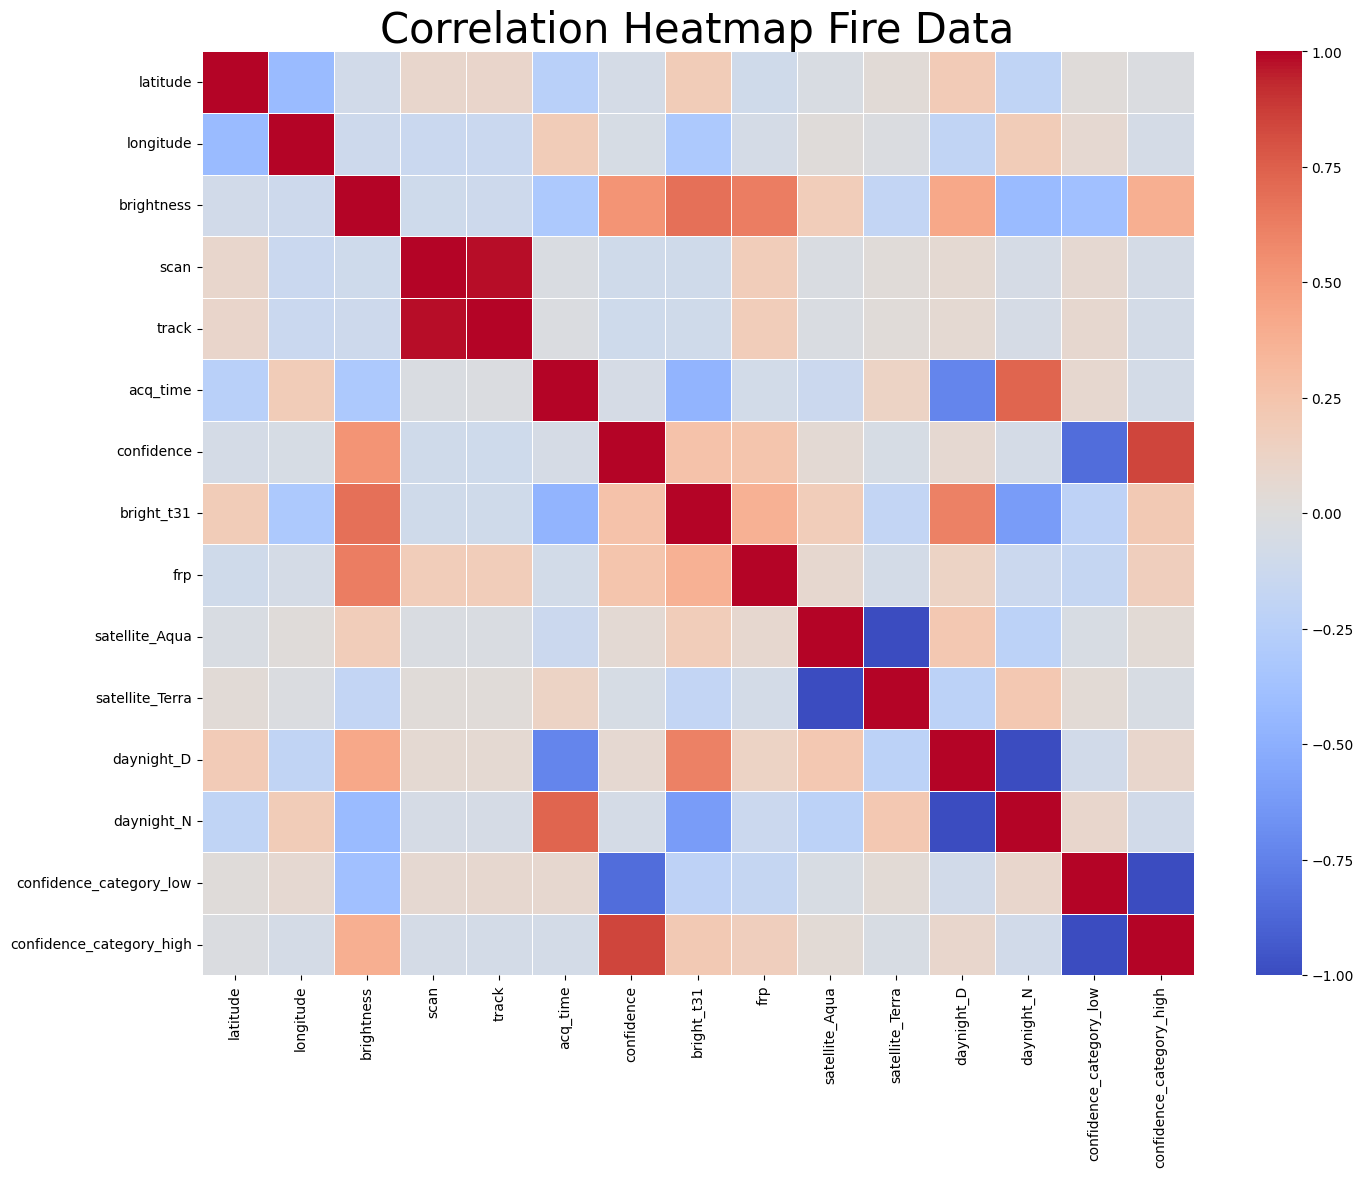

In [ ]:
# Create a correlation matrix
correlation_matrix_one_hot_encoded_fire_data = one_hot_fire_data.corr()

# Set the size of the plot
matplt.figure(figsize=(16, 12))
matplt.title("Correlation Heatmap Fire Data", fontsize=30)

# Create a heatmap of the correlation matrix
sea.heatmap(correlation_matrix_one_hot_encoded_fire_data, annot=False, cmap='coolwarm', linewidths=0.5)

<Axes: title={'center': 'Recheck Correlation Heatmap Fire Data'}>

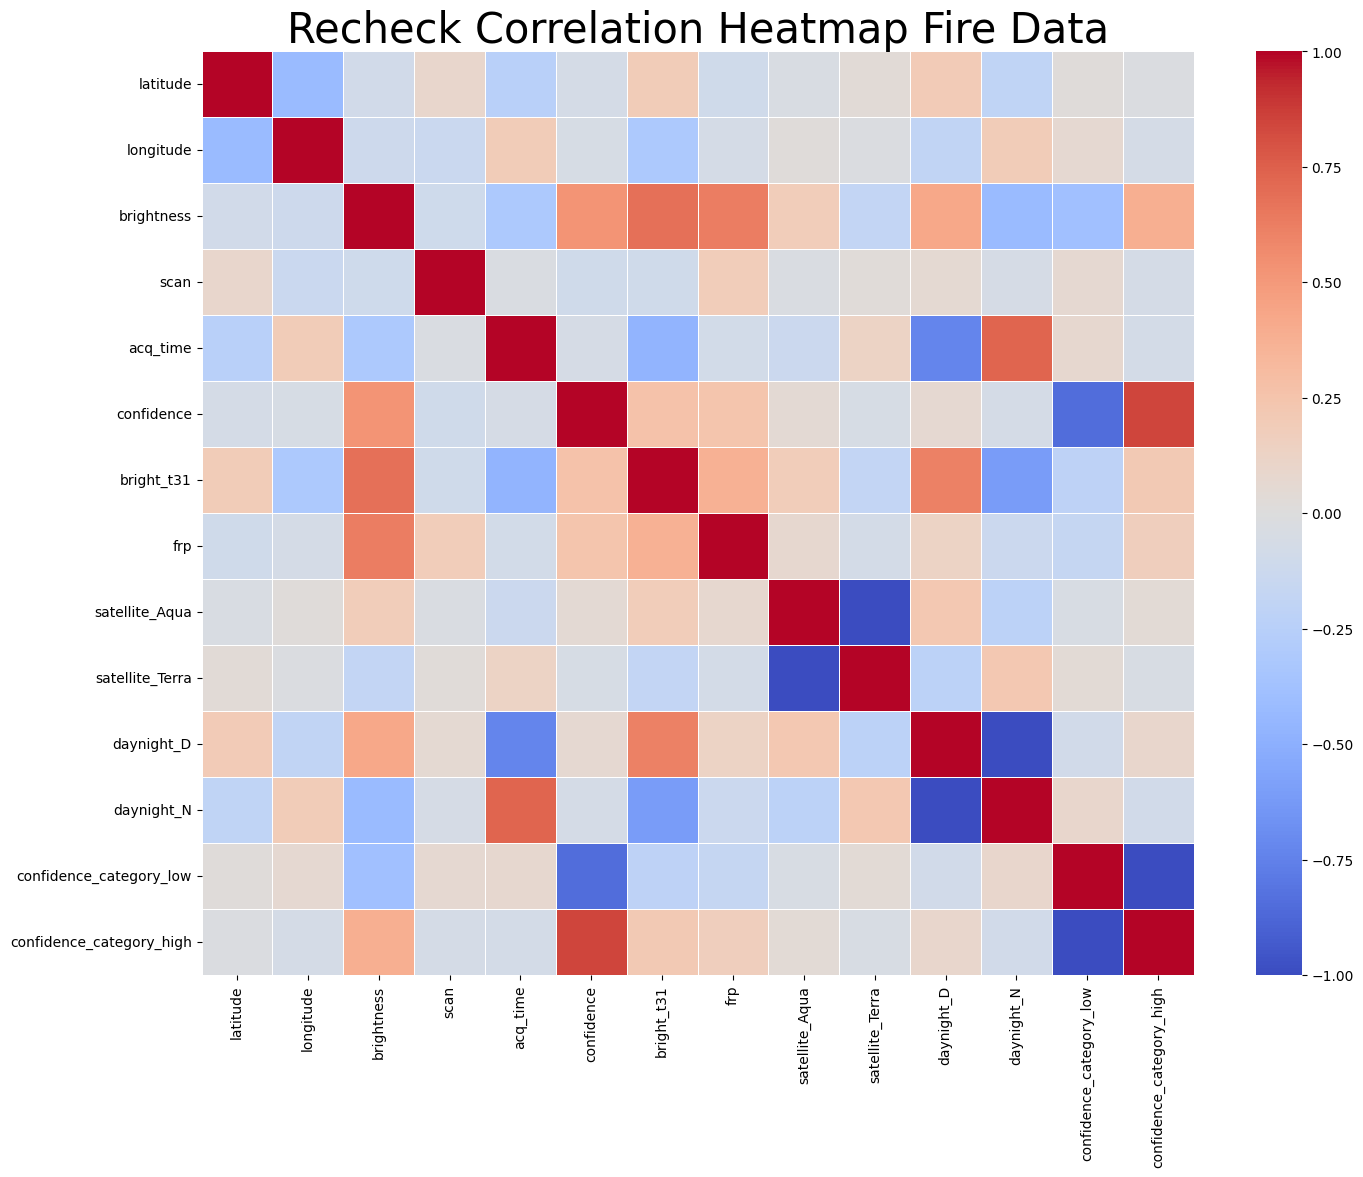

In [ ]:
# Isolate one triangle of the correlation matrix
half_correlation_matrix_one_hot_encoded_fire_data = correlation_matrix_one_hot_encoded_fire_data.where(np.triu(np.ones(correlation_matrix_one_hot_encoded_fire_data.shape), k=1).astype(bool))

# Drop columns with high levels of correlation to other columns
drop_90 = [correlation_column for correlation_column in half_correlation_matrix_one_hot_encoded_fire_data.columns if any(half_correlation_matrix_one_hot_encoded_fire_data[correlation_column] > 0.9 )]

# Update the one-hot encoded dataframes
one_hot_fire_data = one_hot_fire_data.drop(columns=drop_90)

# Create a correlation matrix to recheck
recheck_correlation_matrix_one_hot_encoded_fire_data = one_hot_fire_data.corr()

# Set the size of the plot
matplt.figure(figsize=(16, 12))
matplt.title("Recheck Correlation Heatmap Fire Data", fontsize=30)

# Create a heatmap of the correlation matrix to recheck
sea.heatmap(recheck_correlation_matrix_one_hot_encoded_fire_data, annot=False, cmap='coolwarm', linewidths=0.5)

In [ ]:
# Create a list of numeric columns
select_numeric_only_one_hot_encoded_fire_data = one_hot_fire_data.select_dtypes(include=['number']).columns

# Create a list of columns that are not binary, one-hot encoded or the response variable
scale_columns_numeric_only_one_hot_encoded_fire_data = [
    binary_check_numeric_only_one_hot_encoded_fire_data for binary_check_numeric_only_one_hot_encoded_fire_data in select_numeric_only_one_hot_encoded_fire_data
    if one_hot_fire_data[binary_check_numeric_only_one_hot_encoded_fire_data].nunique() > 2 and binary_check_numeric_only_one_hot_encoded_fire_data != 'Exoplanet_Archive_Disposition'
]

# Perform scaling via the StandardScaler function
scaler_numeric_only_one_hot_encoded = StandardScaler()

# Update the dataframe with the scaled columns
one_hot_fire_data[scale_columns_numeric_only_one_hot_encoded_fire_data] = scaler_numeric_only_one_hot_encoded.fit_transform(one_hot_fire_data[scale_columns_numeric_only_one_hot_encoded_fire_data])

In [ ]:
# Split fire_data into training validation and test sets
train_fire, fire_40 = train_test_split(one_hot_fire_data, test_size=0.4, random_state=6704)
validate_fire, test_fire = train_test_split(fire_40, test_size=0.5, random_state=6704)

# Get the counts for each of the dataframes
count_train_fire = len(train_fire)
count_validate_fire = len(validate_fire)
count_test_fire = len(test_fire)

# Calculate total observations
total_count_fire = count_train_fire + count_validate_fire + count_test_fire

# Calculate the percentage of the total each data set is
percent_train_fire = round((count_train_fire / total_count_fire) * 100,2)
percent_validate_fire = round((count_validate_fire / total_count_fire) * 100,2)
percent_test_fire = round((count_test_fire / total_count_fire) * 100,2)

# Initiate a console
fire_data_split_console = Console()

# Create a table to display the information
fire_data_split = Table(title="[bold]fire Dataset Split[/bold]")

# Add table columns and labels
fire_data_split.add_column("Split", justify="left")
fire_data_split.add_column("Percent", justify="center")
fire_data_split.add_column("Observation Count", justify="center")

# Add table rows and labels
fire_data_split.add_row("Training", f"{percent_train_fire} %", f"{len(train_fire):}" )
fire_data_split.add_row("Validation", f"{percent_validate_fire} %", f"{len(validate_fire):}")
fire_data_split.add_row("Test", f"{percent_test_fire} %", f"{len(test_fire):}")

# Print the table
fire_data_split_console.print(fire_data_split)

             fire Dataset Split             
┏━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Split      ┃ Percent ┃ Observation Count ┃
┡━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Training   │ 60.0 %  │      110155       │
│ Validation │ 20.0 %  │       36719       │
│ Test       │ 20.0 %  │       36719       │
└────────────┴─────────┴───────────────────┘

In [ ]:
predictors_train_categorical_global = train_fire.drop(columns=['confidence', 'confidence_category_low', 'confidence_category_high'])
response_train_categorical_global = train_fire['confidence_category_high']
predictors_validation_categorical_global = validate_fire.drop(columns=['confidence', 'confidence_category_low', 'confidence_category_high'])
response_validation_categorical_global = validate_fire['confidence_category_high']

In [ ]:
predictors_train_continuous_global = train_fire.drop(columns=['confidence', 'confidence_category_low', 'confidence_category_high'])
response_train_continuous_global = train_fire['confidence']
predictors_validation_continuous_global = validate_fire.drop(columns=['confidence', 'confidence_category_low', 'confidence_category_high'])
response_validation_continuous_global = validate_fire['confidence']

<h3>Baseline Model: Logistic Regression</h3>

In [ ]:
# Copy the data into dataframes specific to this model
predictors_train_logistic_regression = predictors_train_categorical_global
response_train_logistic_regression = response_train_categorical_global
predictors_validation_logistic_regression = predictors_validation_categorical_global
response_validation_logistic_regression = response_validation_categorical_global

# Record the time, this will be when the model starts traning
start_time_logistic_regression = time.time()

# Run the model
model_logistic_regression = LogisticRegression().fit(predictors_train_logistic_regression, response_train_logistic_regression)

# Record the time, this will be when the model stops traning
end_time_logistic_regression = time.time()

# Calculate total elapsed time
total_time_logistic_regression = round(end_time_logistic_regression - start_time_logistic_regression,2)

# Get predictions and probabilities
predictions_logistic_regression = model_logistic_regression.predict(predictors_validation_logistic_regression)
probabilities_logistic_regression = model_logistic_regression.predict_proba(predictors_validation_logistic_regression)[:, 1]

# Calculate the ROC-AUC
roc_auc_logistic_regression = round(roc_auc_score(response_validation_logistic_regression, probabilities_logistic_regression)*100,2)

# Create a confusion matrix and get the values
true_negatives_logistic_regression, false_positives_logistic_regression, false_negatives_logistic_regression, true_positives_logistic_regression = confusion_matrix(response_validation_logistic_regression, predictions_logistic_regression).ravel()

# Initiate a console
console_confusion_matrix_logistic_regression = Console()

# Create a table to display the information
table_confusion_matrix_logistic_regression = Table(title="[bold]Confusion Matrix Logistic Regression[/bold]")

# Add table columns and labels
table_confusion_matrix_logistic_regression.add_column("Classification", justify="left")
table_confusion_matrix_logistic_regression.add_column("Count", justify="right")

# Add table rows and labels
table_confusion_matrix_logistic_regression.add_row("True Positives", str(true_positives_logistic_regression))
table_confusion_matrix_logistic_regression.add_row("False Positives", str(false_positives_logistic_regression))
table_confusion_matrix_logistic_regression.add_row("True Negatives", str(true_negatives_logistic_regression))
table_confusion_matrix_logistic_regression.add_row("False Negatives", str(false_negatives_logistic_regression))

# Print the table
console_confusion_matrix_logistic_regression.print(table_confusion_matrix_logistic_regression)

# Create the classification report
classification_report_logistic_regression = classification_report(response_validation_logistic_regression, predictions_logistic_regression, output_dict=True)

# Initiate a console
console_classification_report_logistic_regression = Console()

# Create a table to display the information
table_classification_report_logistic_regression = Table(title="[bold]Classification Report Logistic Regression[/bold]")

# Add table columns and labels
table_classification_report_logistic_regression.add_column("Class", justify="left")
table_classification_report_logistic_regression.add_column("Precision", justify="right")
table_classification_report_logistic_regression.add_column("Recall", justify="right")
table_classification_report_logistic_regression.add_column("F1-Score", justify="right")
table_classification_report_logistic_regression.add_column("Support", justify="right")

# Add table rows and labels
for label_classification_report_logistic_regression, metrics_classification_report_logistic_regression in classification_report_logistic_regression.items():
    if label_classification_report_logistic_regression == 'accuracy':
        continue
    table_classification_report_logistic_regression.add_row(
        str(label_classification_report_logistic_regression),
        f"{metrics_classification_report_logistic_regression['precision']:.4f}",
        f"{metrics_classification_report_logistic_regression['recall']:.4f}",
        f"{metrics_classification_report_logistic_regression['f1-score']:.4f}",
        f"{metrics_classification_report_logistic_regression['support']:.0f}"
    )

# Print the table
console_classification_report_logistic_regression.print(table_classification_report_logistic_regression)

# Initiate a console
console_roc_auc_logistic_regression = Console()

# Create a table to display the information
table_roc_auc_logistic_regression = Table(title="[bold]ROC-AUC Score Logistic Regression[/bold]")

# Add table columns and labels
table_roc_auc_logistic_regression.add_column("Metric", justify="left")
table_roc_auc_logistic_regression.add_column("Percent", justify="right")

# Add table row and label
table_roc_auc_logistic_regression.add_row("ROC-AUC Score", f"{roc_auc_logistic_regression} %")

# Print the table
console_roc_auc_logistic_regression.print(table_roc_auc_logistic_regression)

# Initiate a console
console_accuracy_logistic_regression = Console()

# Create a table to display the information
table_accuracy_logistic_regression = Table(title="[bold]Accuracy Logistic Regression[/bold]")

# Add table columns and labels
table_accuracy_logistic_regression.add_column("Metric", justify="left")
table_accuracy_logistic_regression.add_column("Percent", justify="right")

# Add table row and label
table_accuracy_logistic_regression.add_row("Accuracy", f"{round(classification_report_logistic_regression['accuracy']*100,2)} %")

# Print the table
console_accuracy_logistic_regression.print(table_accuracy_logistic_regression)

# Calculate the logarithmic loss
log_loss_logistic_regression = log_loss(response_validation_logistic_regression, probabilities_logistic_regression)

# Initiate a console
console_log_loss_logistic_regression = Console()

# Create a table to display the information
table_log_loss_logistic_regression = Table(title="[bold]Log Loss Logistic Regression[/bold]")

# Add table columns and labels
table_log_loss_logistic_regression.add_column("Metric", justify="left")
table_log_loss_logistic_regression.add_column("Value", justify="right")

# Add table row and label
table_log_loss_logistic_regression.add_row("Log Loss", f"{round(log_loss_logistic_regression,5)}")

# Print the table
console_log_loss_logistic_regression.print(table_log_loss_logistic_regression)

# Initiate a console
console_logistic_regression_report = Console()

# Create a table to display the information
table_logistic_regression_report = Table(title="[bold]Logistic Regression Model Training Time[/bold]")

# Add table columns and labels
table_logistic_regression_report.add_column("Information", justify="left")
table_logistic_regression_report.add_column("Value", justify="left")

# Add table rows and labels
table_logistic_regression_report.add_row(f"Training Time", f"{total_time_logistic_regression} s")

# Print the table
console_logistic_regression_report.print(table_logistic_regression_report)


 Confusion Matrix Logistic 
        Regression         
┏━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Classification  ┃ Count ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ True Positives  │ 24526 │
│ False Positives │  4085 │
│ True Negatives  │  5600 │
│ False Negatives │  2508 │
└─────────────────┴───────┘

        Classification Report Logistic Regression         
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┓
┃ Class        ┃ Precision ┃ Recall ┃ F1-Score ┃ Support ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━┩
│ False        │    0.6907 │ 0.5782 │   0.6295 │    9685 │
│ True         │    0.8572 │ 0.9072 │   0.8815 │   27034 │
│ macro avg    │    0.7739 │ 0.7427 │   0.7555 │   36719 │
│ weighted avg │    0.8133 │ 0.8204 │   0.8150 │   36719 │
└──────────────┴───────────┴────────┴──────────┴─────────┘

  ROC-AUC Score Logistic   
        Regression         
┏━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Metric        ┃ Percent ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ ROC-AUC Score │ 87.69 % │
└───────────────┴─────────┘

  Accuracy Logistic   
      Regression      
┏━━━━━━━━━━┳━━━━━━━━━┓
┃ Metric   ┃ Percent ┃
┡━━━━━━━━━━╇━━━━━━━━━┩
│ Accuracy │ 82.04 % │
└──────────┴─────────┘

  Log Loss Logistic   
      Regression      
┏━━━━━━━━━━┳━━━━━━━━━┓
┃ Metric   ┃   Value ┃
┡━━━━━━━━━━╇━━━━━━━━━┩
│ Log Loss │ 0.38847 │
└──────────┴─────────┘

Logistic Regression Model 
      Training Time       
┏━━━━━━━━━━━━━━━┳━━━━━━━━┓
┃ Information   ┃ Value  ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━┩
│ Training Time │ 0.33 s │
└───────────────┴────────┘

<h3>Feature Importance</h3>

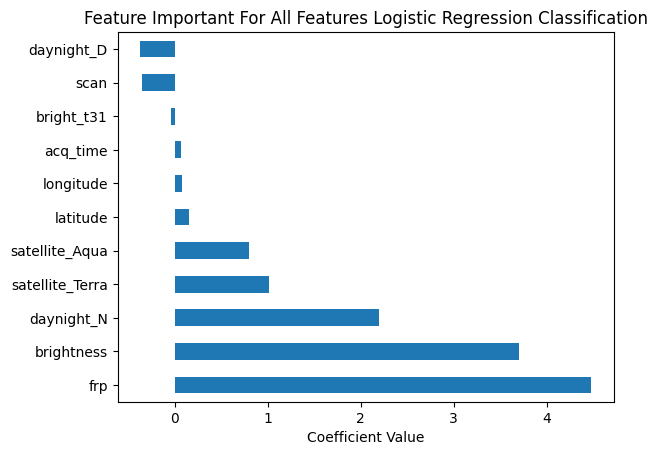

In [ ]:
# Extract coefficients and match them to feature names
importance = model_logistic_regression.coef_[0]
feature_names = predictors_train_logistic_regression.columns

# Create a DataFrame for sorting
feat_importances = pd.Series(importance, index=feature_names)

# Plot the features ccording to the coefficients
feat_importances.nlargest(20).plot(kind='barh')
matplt.title("Feature Important For All Features Logistic Regression Classification")
matplt.xlabel("Coefficient Value")
matplt.show()

In [ ]:
# Initialize a logistic regression model and specify max iterations
logistic_regression_exhaustive_selector = LogisticRegression(max_iter=1000)

# Print title
print("\033[1m   Best Feature Results\033[0m")

# Set up the exhaustive feature selection function
selector_logistic_regression = ExhaustiveFeatureSelector(logistic_regression_exhaustive_selector, scoring='accuracy', cv=5)

# Fit the logisitc regresson model
selector_logistic_regression.fit(predictors_train_logistic_regression, response_train_logistic_regression)

# Extrace best features to maximize accuracy
best_features_logistic_regression = selector_logistic_regression.best_idx_
exhaustive_features_logistic_regression = predictors_train_logistic_regression.columns[list(best_features_logistic_regression)]

# Print the results
print("Best feature subset found for Logistic Regression:", list(exhaustive_features_logistic_regression))
print(f"Best Validation Accuracy achieved: {selector_logistic_regression.best_score_:.2%}")

   Best Feature Results


Features: 11/11

Best feature subset found for Logistic Regression: ['brightness']
Best Validation Accuracy achieved: 75.81%


<h3>Baseline Model: Linear Regression</h3>

In [ ]:
# Copy the data into dataframes specific to this model
predictors_train_linear_regression = predictors_train_continuous_global
response_train_linear_regression = response_train_continuous_global
predictors_validation_linear_regression = predictors_validation_continuous_global
response_validation_linear_regression = response_validation_continuous_global

# Record the time, this will be when the model starts traning
start_time_linear_regression = time.time()

# Run the model
model_linear_regression = LinearRegression().fit(predictors_train_linear_regression, response_train_linear_regression)

# Record the time, this will be when the model stops traning
end_time_linear_regression = time.time()

# Calculate total elapsed time
total_time_linear_regression = round(end_time_linear_regression - start_time_linear_regression,2)

# Get predictions and probabilities
predictions_linear_regression = model_linear_regression.predict(predictors_validation_linear_regression)

# Calculate metrics
mae_model_linear_regression = round(mean_absolute_error(response_validation_linear_regression, predictions_linear_regression),5)
mse_model_linear_regression = round(mean_squared_error(response_validation_linear_regression, predictions_linear_regression),5)
rmse_model_linear_regression = round(np.sqrt(mse_model_linear_regression),5)
r2_model_linear_regression = round(r2_score(response_validation_linear_regression, predictions_linear_regression),5)

# Initiate a console
console_linear_regression_report = Console()

# Create a table to display the information
table_linear_regression_report = Table(title="[bold]Linear Regression Model Report[/bold]")

# Add table columns and labels
table_linear_regression_report.add_column("Information", justify="left")
table_linear_regression_report.add_column("Value", justify="left")

# Add table rows and labels
table_linear_regression_report.add_row(f"Training Time", f"{total_time_linear_regression} s")
table_linear_regression_report.add_row(f"MAE", f"{mae_model_linear_regression}")
table_linear_regression_report.add_row(f"MSE", f"{mse_model_linear_regression}")
table_linear_regression_report.add_row(f"RMSE", f"{rmse_model_linear_regression}")
table_linear_regression_report.add_row(f"R squared", f"{r2_model_linear_regression}")

# Print the table
console_linear_regression_report.print(table_linear_regression_report)

  Linear Regression Model  
          Report           
┏━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Information   ┃ Value   ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ Training Time │ 0.13 s  │
│ MAE           │ 0.64797 │
│ MSE           │ 0.6642  │
│ RMSE          │ 0.81498 │
│ R squared     │ 0.33048 │
└───────────────┴─────────┘

            Feature  Coefficient
2        brightness     0.813701
6               frp    -0.196759
9        daynight_D    -0.188208
10       daynight_N     0.188208
5        bright_t31    -0.116081
0          latitude     0.033784
1         longitude    -0.032274
3              scan     0.016138
8   satellite_Terra     0.014919
7    satellite_Aqua    -0.014919
4          acq_time     0.008580


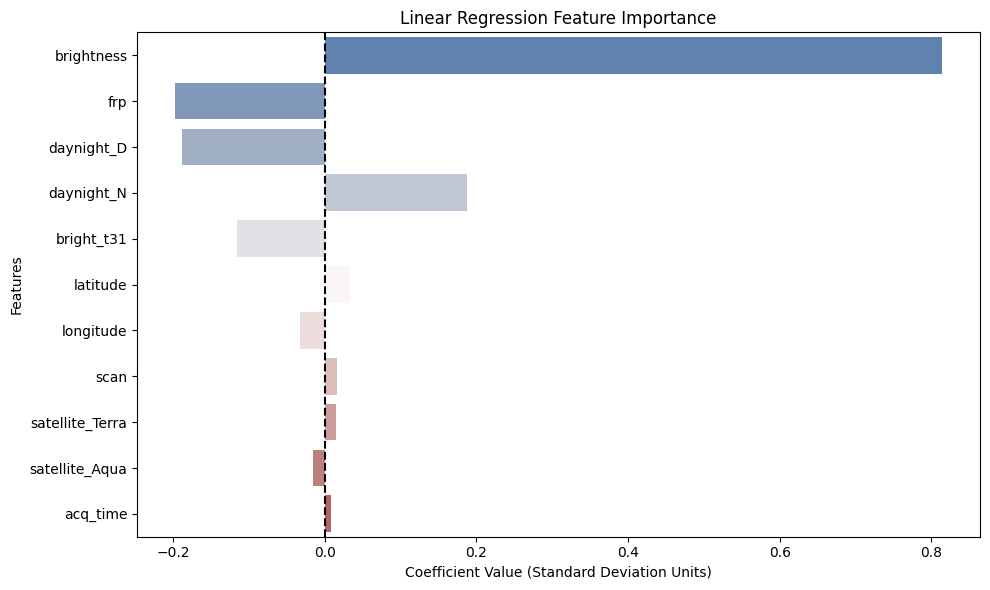

In [ ]:
# Extract features and map them to their coefficients
importance_linear_regression = pd.DataFrame({"Feature": predictors_train_linear_regression.columns, "Coefficient": model_linear_regression.coef_})
importance_linear_regression["Abs_Coefficient"] = importance_linear_regression["Coefficient"].abs()
importance_linear_regression = importance_linear_regression.sort_values(by="Abs_Coefficient", ascending=False).drop(columns=["Abs_Coefficient"])

# Print the results
display(HTML("<h2>Standardized Feature Importance Linear Regression</h2>"))
print(importance_linear_regression)

# Plot the results
matplt.figure(figsize=(10, 6))
sea.barplot(x="Coefficient", y="Feature", data=importance_linear_regression, palette="vlag")
matplt.axvline(x=0, color="black", linestyle="--")
matplt.title("Linear Regression Feature Importance")
matplt.xlabel("Coefficient Value (Standard Deviation Units)")
matplt.ylabel("Features")
matplt.tight_layout()
matplt.show()

In [ ]:
# Initialize a linear regression model
linear_regression_exhaustive_selector = LinearRegression()

# Print title
print("\033[1m   Best Feature Results\033[0m")

# Set up the exhaustive feature selection function
linear_regression_selector = ExhaustiveFeatureSelector(linear_regression_exhaustive_selector, scoring='r2', cv=5)

# Fit the linear regresson model
linear_regression_selector.fit(predictors_train_linear_regression, response_train_linear_regression)

# Extrace best features to minimize R²
best_features_linear_regression = linear_regression_selector.best_idx_
exhaustive_features_linear_regression = predictors_train_linear_regression.columns[list(best_features_linear_regression)]

# Print the results
print("Best feature subset found for Linear Regression:", list(exhaustive_features_linear_regression))
print(f"Best R² Score achieved: {linear_regression_selector.best_score_:.4f}")

   Best Feature Results


Features: 11/11

Best feature subset found for Linear Regression: ['brightness']
Best R² Score achieved: 0.2748


<h3>Experiment: Dimension Reduction With PCA</h3>
<p>This section uses PCA to reduce the predictor space while keeping 95% of the variance, then fits Logistic Regression on the reduced predictors.</p>

   PCA Dimension Reduction Logistic   
          Regression Report           
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Information              ┃ Value   ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ Training Time            │ 0.47 s  │
│ Original Predictor Count │ 11      │
│ PCA Component Count      │ 7       │
│ Variance Explained       │ 95.83 % │
│ Validation Accuracy      │ 81.78 % │
│ Validation ROC-AUC       │ 87.48 % │
│ True Negatives           │ 5469    │
│ False Positives          │ 4216    │
│ False Negatives          │ 2476    │
│ True Positives           │ 24558   │
└──────────────────────────┴─────────┘

   PCA Dimension Reduction Classification Report
                 precision    recall  f1-score   support

 Low Confidence       0.69      0.56      0.62      9685
High Confidence       0.85      0.91      0.88     27034

       accuracy                           0.82     36719
      macro avg       0.77      0.74      0.75     36719
   weighted avg       0.81      0.82      0.81     36719



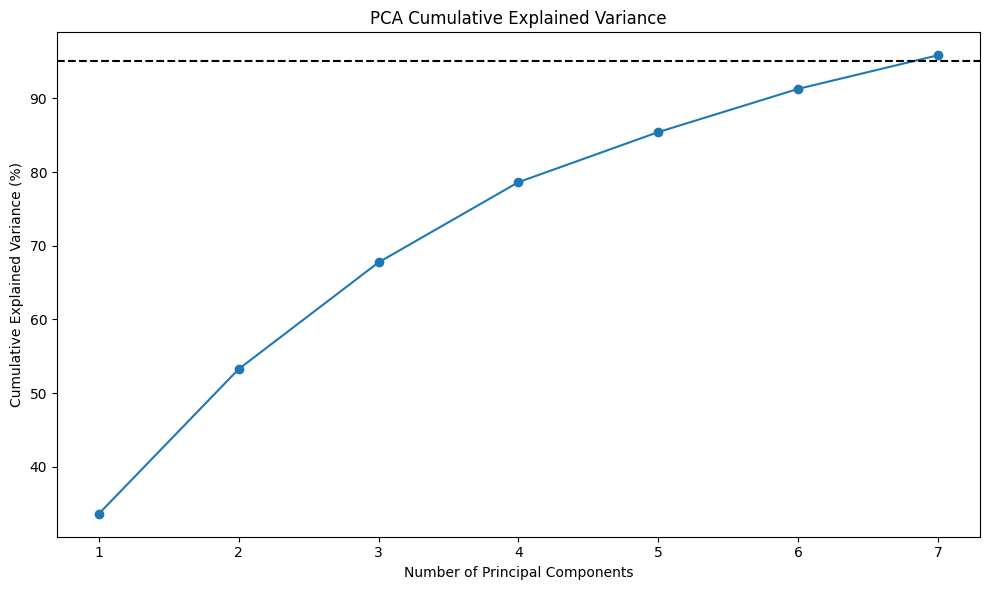

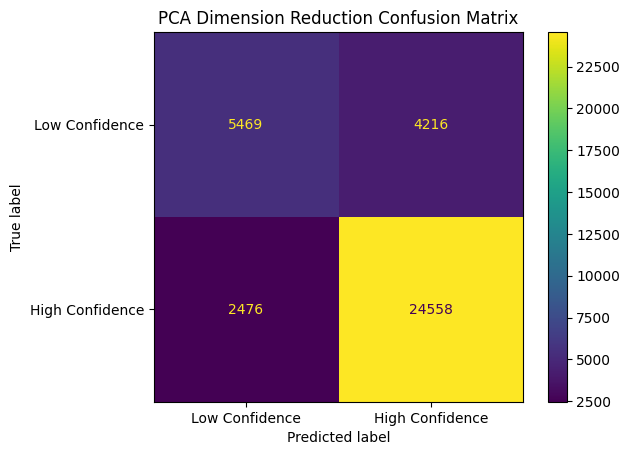

In [ ]:
# Import in the methods needed for dimension reduction
from sklearn.decomposition import PCA

# Copy the data into dataframes specific to this model
predictors_train_pca_dimension_reduction = predictors_train_categorical_global.copy()
response_train_pca_dimension_reduction = response_train_categorical_global.copy()
predictors_validation_pca_dimension_reduction = predictors_validation_categorical_global.copy()
response_validation_pca_dimension_reduction = response_validation_categorical_global.copy()

# Record the time, this will be when the dimension reduction model starts training
start_time_pca_dimension_reduction = time.time()

# Run PCA and keep enough principal components to explain 95% of the variance
model_pca_dimension_reduction = PCA(n_components=0.95, random_state=6704)
predictors_train_reduced_pca_dimension_reduction = model_pca_dimension_reduction.fit_transform(predictors_train_pca_dimension_reduction)
predictors_validation_reduced_pca_dimension_reduction = model_pca_dimension_reduction.transform(predictors_validation_pca_dimension_reduction)

# Run a logistic regression model using the reduced PCA predictors
model_logistic_regression_pca_dimension_reduction = LogisticRegression(max_iter=1000)
model_logistic_regression_pca_dimension_reduction.fit(predictors_train_reduced_pca_dimension_reduction, response_train_pca_dimension_reduction)

# Record the time, this will be when the dimension reduction model stops training
end_time_pca_dimension_reduction = time.time()

# Calculate total elapsed time
total_time_pca_dimension_reduction = round(end_time_pca_dimension_reduction - start_time_pca_dimension_reduction, 2)

# Get predictions and probabilities
predictions_pca_dimension_reduction = model_logistic_regression_pca_dimension_reduction.predict(predictors_validation_reduced_pca_dimension_reduction)
probabilities_pca_dimension_reduction = model_logistic_regression_pca_dimension_reduction.predict_proba(predictors_validation_reduced_pca_dimension_reduction)[:, 1]

# Calculate model metrics
accuracy_pca_dimension_reduction = round(accuracy_score(response_validation_pca_dimension_reduction, predictions_pca_dimension_reduction) * 100, 2)
roc_auc_pca_dimension_reduction = round(roc_auc_score(response_validation_pca_dimension_reduction, probabilities_pca_dimension_reduction) * 100, 2)

# Create a confusion matrix and get the values
true_negatives_pca_dimension_reduction, false_positives_pca_dimension_reduction, false_negatives_pca_dimension_reduction, true_positives_pca_dimension_reduction = confusion_matrix(
    response_validation_pca_dimension_reduction,
    predictions_pca_dimension_reduction,
    labels=[False, True]
).ravel()

# Get PCA information
original_feature_count_pca_dimension_reduction = predictors_train_pca_dimension_reduction.shape[1]
component_count_pca_dimension_reduction = model_pca_dimension_reduction.n_components_
variance_explained_pca_dimension_reduction = round(model_pca_dimension_reduction.explained_variance_ratio_.sum() * 100, 2)

# Initiate a console
console_pca_dimension_reduction_report = Console()

# Create a table to display the information
table_pca_dimension_reduction_report = Table(title="[bold]PCA Dimension Reduction Logistic Regression Report[/bold]")

# Add table columns and labels
table_pca_dimension_reduction_report.add_column("Information", justify="left")
table_pca_dimension_reduction_report.add_column("Value", justify="left")

# Add table rows and labels
table_pca_dimension_reduction_report.add_row("Training Time", f"{total_time_pca_dimension_reduction} s")
table_pca_dimension_reduction_report.add_row("Original Predictor Count", f"{original_feature_count_pca_dimension_reduction}")
table_pca_dimension_reduction_report.add_row("PCA Component Count", f"{component_count_pca_dimension_reduction}")
table_pca_dimension_reduction_report.add_row("Variance Explained", f"{variance_explained_pca_dimension_reduction} %")
table_pca_dimension_reduction_report.add_row("Validation Accuracy", f"{accuracy_pca_dimension_reduction} %")
table_pca_dimension_reduction_report.add_row("Validation ROC-AUC", f"{roc_auc_pca_dimension_reduction} %")
table_pca_dimension_reduction_report.add_row("True Negatives", f"{true_negatives_pca_dimension_reduction}")
table_pca_dimension_reduction_report.add_row("False Positives", f"{false_positives_pca_dimension_reduction}")
table_pca_dimension_reduction_report.add_row("False Negatives", f"{false_negatives_pca_dimension_reduction}")
table_pca_dimension_reduction_report.add_row("True Positives", f"{true_positives_pca_dimension_reduction}")

# Print the table
console_pca_dimension_reduction_report.print(table_pca_dimension_reduction_report)

# Print classification report
print("\033[1m   PCA Dimension Reduction Classification Report\033[0m")
print(classification_report(
    response_validation_pca_dimension_reduction,
    predictions_pca_dimension_reduction,
    labels=[False, True],
    target_names=["Low Confidence", "High Confidence"],
    zero_division=0
))

# Calculate cumulative explained variance
cumulative_variance_pca_dimension_reduction = np.cumsum(model_pca_dimension_reduction.explained_variance_ratio_)

# Plot the cumulative explained variance
matplt.figure(figsize=(10, 6))
matplt.plot(
    range(1, len(cumulative_variance_pca_dimension_reduction) + 1),
    cumulative_variance_pca_dimension_reduction * 100,
    marker="o"
)
matplt.axhline(y=95, color="black", linestyle="--")
matplt.title("PCA Cumulative Explained Variance")
matplt.xlabel("Number of Principal Components")
matplt.ylabel("Cumulative Explained Variance (%)")
matplt.tight_layout()
matplt.show()

# Display the confusion matrix
confusion_matrix_display_pca_dimension_reduction = ConfusionMatrixDisplay.from_predictions(
    response_validation_pca_dimension_reduction,
    predictions_pca_dimension_reduction,
    display_labels=["Low Confidence", "High Confidence"]
)
matplt.title("PCA Dimension Reduction Confusion Matrix")
matplt.show()

<h3>Experiment: Clustering With K-Means</h3>
<p>This section uses PCA for noise reduction, tests different K values on a sample for speed, and fits the final K-Means clustering model on the full training set.</p>

        K-Means Clustering Report        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Information                 ┃ Value   ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ Training Time               │ 1.42 s  │
│ Original Predictor Count    │ 11      │
│ PCA Component Count         │ 7       │
│ Variance Explained          │ 95.83 % │
│ K-Selection Sample Size     │ 5000    │
│ Best Number of Clusters     │ 9       │
│ Training Silhouette Score   │ 0.3038  │
│ Validation Silhouette Score │ 0.3198  │
└─────────────────────────────┴─────────┘

,K,Inertia,Silhouette Score
0,2,28339.030076,0.290524
1,3,25164.274758,0.291122
2,4,21796.937518,0.298019
3,5,19754.984441,0.305016
4,6,16076.982967,0.320260
5,7,15209.874563,0.320320
6,8,13883.038289,0.319216
7,9,12675.095707,0.329592
8,10,11935.138861,0.325194


         K-Means Cluster Counts          
┏━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Cluster ┃ Observation Count ┃ Percent ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│    0    │       7265        │  6.6 %  │
│    1    │       23978       │ 21.77 % │
│    2    │       28822       │ 26.16 % │
│    3    │       11673       │ 10.6 %  │
│    4    │       2418        │  2.2 %  │
│    5    │       11387       │ 10.34 % │
│    6    │       5202        │ 4.72 %  │
│    7    │       9385        │ 8.52 %  │
│    8    │       10025       │  9.1 %  │
└─────────┴───────────────────┴─────────┘

High Confidence,0,1
Cluster,,
0,2239,5026
1,5306,18672
2,8967,19855
3,2914,8759
4,8,2410
5,3425,7962
6,2153,3049
7,2569,6816
8,1485,8540


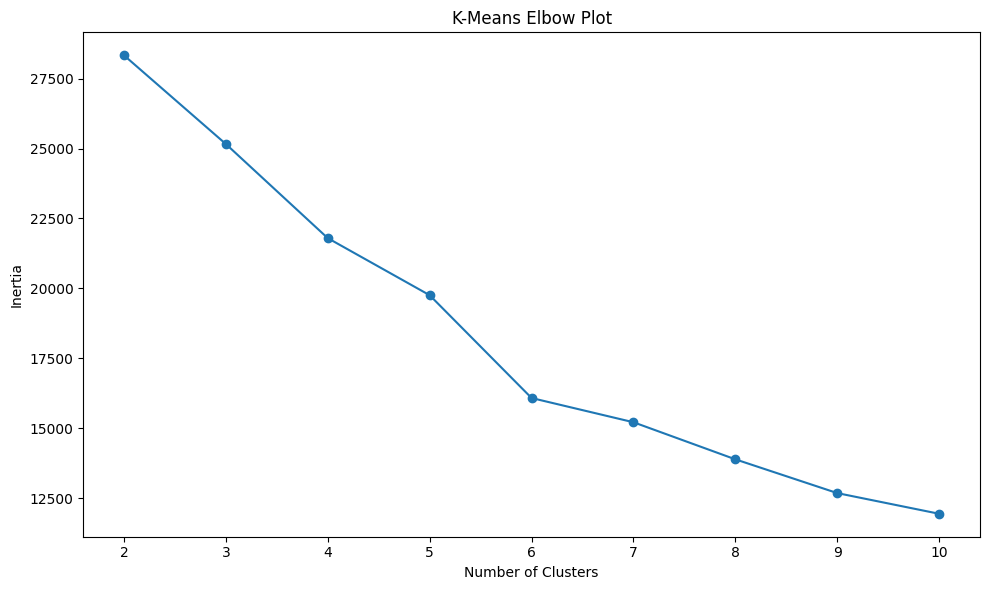

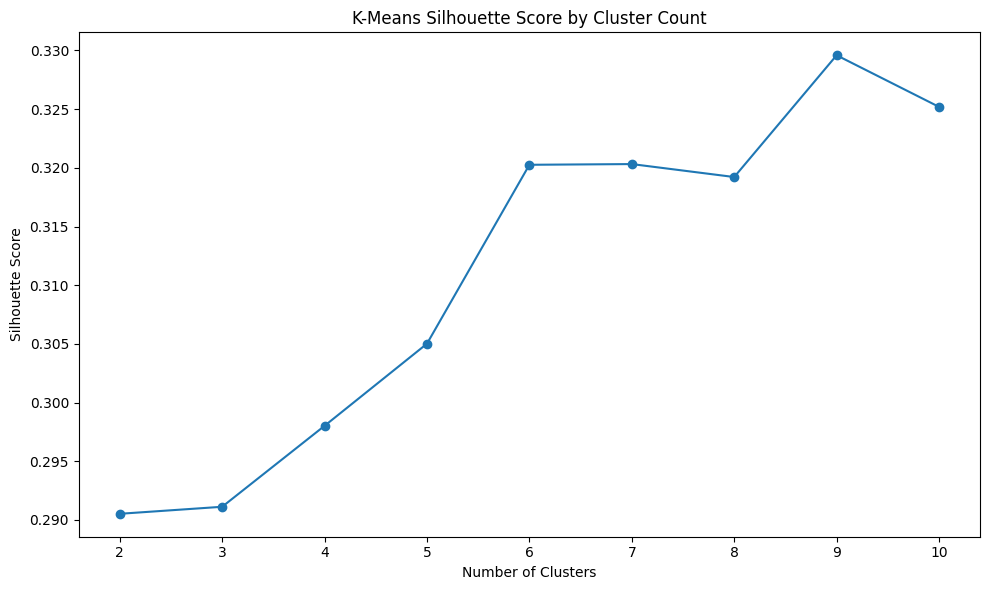

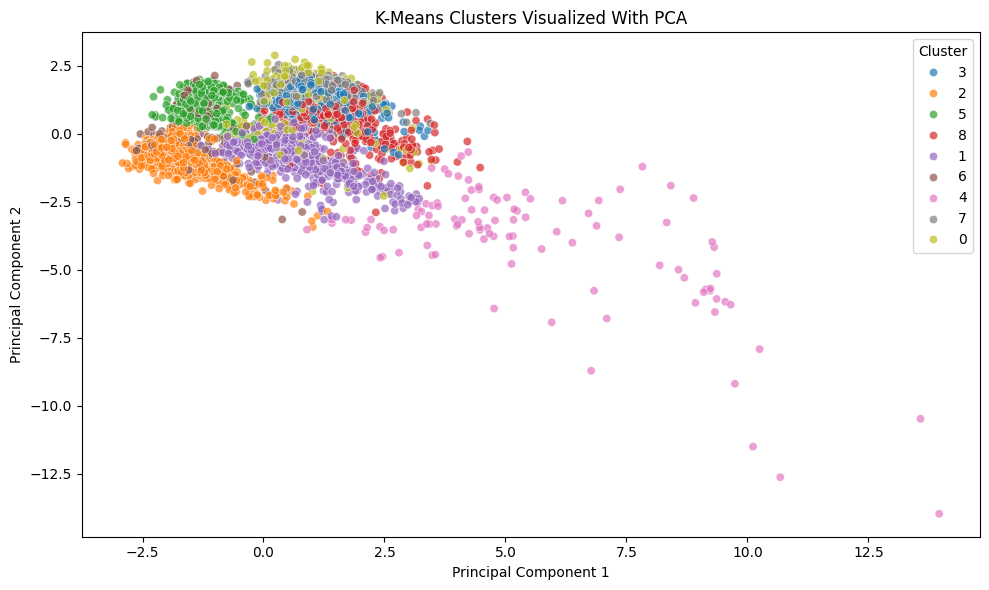

In [ ]:
# Import in the methods needed for clustering
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Copy the data into dataframes specific to this model
predictors_train_clustering = predictors_train_categorical_global.copy()
response_train_clustering = response_train_categorical_global.copy()
predictors_validation_clustering = predictors_validation_categorical_global.copy()
response_validation_clustering = response_validation_categorical_global.copy()

# Record the time, this will be when the clustering process starts training
start_time_clustering = time.time()

# Run PCA before clustering to reduce noise while keeping 95% of the variance
model_pca_clustering = PCA(n_components=0.95, random_state=6704)
predictors_train_reduced_clustering = model_pca_clustering.fit_transform(predictors_train_clustering)
predictors_validation_reduced_clustering = model_pca_clustering.transform(predictors_validation_clustering)

# Sample the reduced training data so testing several K values runs quickly on this large dataset
sample_size_clustering = min(5000, len(predictors_train_reduced_clustering))
random_generator_clustering = np.random.default_rng(6704)
sample_index_clustering = random_generator_clustering.choice(
    len(predictors_train_reduced_clustering),
    size=sample_size_clustering,
    replace=False
)
predictors_train_sample_clustering = predictors_train_reduced_clustering[sample_index_clustering]

# Create k values to test for K-Means clustering
maximum_k_clustering = min(10, sample_size_clustering - 1)
k_values_clustering = list(range(2, maximum_k_clustering + 1))

# Make sure there are enough observations for clustering
if len(k_values_clustering) == 0:
    raise ValueError("K-Means clustering needs at least 3 training observations to compare cluster counts.")

# Create empty lists to hold clustering results
inertia_scores_clustering = []
silhouette_scores_clustering = []

# Loop through possible k values and collect inertia and silhouette scores
for k_clustering in k_values_clustering:

    # Run K-Means for this k value using the sample
    model_kmeans_test_clustering = KMeans(
        n_clusters=k_clustering,
        random_state=6704,
        n_init=1,
        max_iter=50,
        algorithm="elkan"
    )
    predictions_train_test_clustering = model_kmeans_test_clustering.fit_predict(predictors_train_sample_clustering)

    # Store inertia
    inertia_scores_clustering.append(model_kmeans_test_clustering.inertia_)

    # Store silhouette score only if at least 2 clusters were created
    if len(np.unique(predictions_train_test_clustering)) > 1:
        silhouette_scores_clustering.append(silhouette_score(
            predictors_train_sample_clustering,
            predictions_train_test_clustering,
            sample_size=min(1000, len(predictors_train_sample_clustering)),
            random_state=6704
        ))
    else:
        silhouette_scores_clustering.append(np.nan)

# Select the k value with the highest silhouette score
silhouette_scores_for_selection_clustering = np.nan_to_num(silhouette_scores_clustering, nan=-1)
best_k_index_clustering = int(np.argmax(silhouette_scores_for_selection_clustering))
best_k_clustering = k_values_clustering[best_k_index_clustering]

# Run the final K-Means clustering model on the full reduced training data
model_kmeans_clustering = KMeans(
    n_clusters=best_k_clustering,
    random_state=6704,
    n_init=1,
    max_iter=50,
    algorithm="elkan"
)
predictions_train_kmeans_clustering = model_kmeans_clustering.fit_predict(predictors_train_reduced_clustering)
predictions_validation_kmeans_clustering = model_kmeans_clustering.predict(predictors_validation_reduced_clustering)

# Record the time, this will be when the clustering process stops training
end_time_clustering = time.time()

# Calculate total elapsed time
total_time_clustering = round(end_time_clustering - start_time_clustering, 2)

# Calculate final silhouette scores using a sample so the notebook runs quickly
silhouette_train_clustering = silhouette_score(
    predictors_train_reduced_clustering,
    predictions_train_kmeans_clustering,
    sample_size=min(1000, len(predictors_train_reduced_clustering)),
    random_state=6704
)

# Calculate validation silhouette score only if at least 2 clusters are represented
if len(np.unique(predictions_validation_kmeans_clustering)) > 1:
    silhouette_validation_clustering = silhouette_score(
        predictors_validation_reduced_clustering,
        predictions_validation_kmeans_clustering,
        sample_size=min(1000, len(predictors_validation_reduced_clustering)),
        random_state=6704
    )
else:
    silhouette_validation_clustering = np.nan

# Get PCA information
original_feature_count_clustering = predictors_train_clustering.shape[1]
component_count_clustering = model_pca_clustering.n_components_
variance_explained_clustering = round(model_pca_clustering.explained_variance_ratio_.sum() * 100, 2)

# Initiate a console
console_clustering_report = Console()

# Create a table to display the information
table_clustering_report = Table(title="[bold]K-Means Clustering Report[/bold]")

# Add table columns and labels
table_clustering_report.add_column("Information", justify="left")
table_clustering_report.add_column("Value", justify="left")

# Add table rows and labels
table_clustering_report.add_row("Training Time", f"{total_time_clustering} s")
table_clustering_report.add_row("Original Predictor Count", f"{original_feature_count_clustering}")
table_clustering_report.add_row("PCA Component Count", f"{component_count_clustering}")
table_clustering_report.add_row("Variance Explained", f"{variance_explained_clustering} %")
table_clustering_report.add_row("K-Selection Sample Size", f"{sample_size_clustering}")
table_clustering_report.add_row("Best Number of Clusters", f"{best_k_clustering}")
table_clustering_report.add_row("Training Silhouette Score", f"{round(silhouette_train_clustering, 4)}")
table_clustering_report.add_row("Validation Silhouette Score", f"{round(silhouette_validation_clustering, 4) if not np.isnan(silhouette_validation_clustering) else 'Not available'}")

# Print the table
console_clustering_report.print(table_clustering_report)

# Create a dataframe for k comparison results
k_results_clustering = pd.DataFrame({
    "K": k_values_clustering,
    "Inertia": inertia_scores_clustering,
    "Silhouette Score": silhouette_scores_clustering
})

# Print title
display(HTML("<h3>K-Means Cluster Count Comparison</h3>"))

# Print table
display(k_results_clustering)

# Create a dataframe for cluster counts
cluster_counts_clustering = pd.Series(predictions_train_kmeans_clustering, name="Cluster").value_counts().sort_index().reset_index()
cluster_counts_clustering.columns = ["Cluster", "Observation Count"]

# Calculate cluster percentages
cluster_counts_clustering["Percent"] = round((cluster_counts_clustering["Observation Count"] / len(predictions_train_kmeans_clustering)) * 100, 2)

# Initiate a console
console_cluster_counts_clustering = Console()

# Create a table to display the information
table_cluster_counts_clustering = Table(title="[bold]K-Means Cluster Counts[/bold]")

# Add table columns and labels
table_cluster_counts_clustering.add_column("Cluster", justify="center")
table_cluster_counts_clustering.add_column("Observation Count", justify="center")
table_cluster_counts_clustering.add_column("Percent", justify="center")

# Add table rows and labels
for index_cluster_counts_clustering, cluster_count_row_clustering in cluster_counts_clustering.iterrows():
    table_cluster_counts_clustering.add_row(
        f"{int(cluster_count_row_clustering['Cluster'])}",
        f"{int(cluster_count_row_clustering['Observation Count'])}",
        f"{cluster_count_row_clustering['Percent']} %"
    )

# Print the table
console_cluster_counts_clustering.print(table_cluster_counts_clustering)

# Compare clusters to the actual confidence category without using the target to create clusters
cluster_confidence_crosstab_clustering = pd.crosstab(
    pd.Series(predictions_train_kmeans_clustering, name="Cluster"),
    pd.Series(response_train_clustering.astype(int).values, name="High Confidence")
)

# Print title
display(HTML("<h3>Cluster vs Actual Confidence Category</h3>"))

# Print table
display(cluster_confidence_crosstab_clustering)

# Plot inertia for each k value
matplt.figure(figsize=(10, 6))
matplt.plot(k_values_clustering, inertia_scores_clustering, marker="o")
matplt.title("K-Means Elbow Plot")
matplt.xlabel("Number of Clusters")
matplt.ylabel("Inertia")
matplt.tight_layout()
matplt.show()

# Plot silhouette score for each k value
matplt.figure(figsize=(10, 6))
matplt.plot(k_values_clustering, silhouette_scores_clustering, marker="o")
matplt.title("K-Means Silhouette Score by Cluster Count")
matplt.xlabel("Number of Clusters")
matplt.ylabel("Silhouette Score")
matplt.tight_layout()
matplt.show()

# Run a 2-component PCA only for visualization
model_pca_plot_clustering = PCA(n_components=2, random_state=6704)
predictors_train_plot_clustering = model_pca_plot_clustering.fit_transform(predictors_train_clustering)

# Create a dataframe for the cluster scatterplot
plot_data_clustering = pd.DataFrame({
    "PC1": predictors_train_plot_clustering[:, 0],
    "PC2": predictors_train_plot_clustering[:, 1],
    "Cluster": predictions_train_kmeans_clustering.astype(str),
    "High Confidence": response_train_clustering.astype(int).values
})

# Sample the data for a cleaner plot if the dataset is large
if len(plot_data_clustering) > 5000:
    plot_data_clustering = plot_data_clustering.sample(n=5000, random_state=6704)

# Plot the clusters using the first two principal components
matplt.figure(figsize=(10, 6))
sea.scatterplot(data=plot_data_clustering, x="PC1", y="PC2", hue="Cluster", alpha=0.7)
matplt.title("K-Means Clusters Visualized With PCA")
matplt.xlabel("Principal Component 1")
matplt.ylabel("Principal Component 2")
matplt.tight_layout()
matplt.show()


<h3>Experiment: Lasso and Ridge via Elastic Net Regression</h3>

Elastic net blends the L1 (Lasso) and L2 (Ridge) penalties together. The l1_ratio controls the mix of these: l1_ratio = 1 is the pure Lasso, with Ridge values approaching near 0, while the values that are in between are a true elastic net. By cross-validating over a grid of l1_ratio and penalty strengths alpha, a single search covers "lasso and ridge via elastic net".
The continuous response (scaled confidence) is used so the results are directly comparable to the Linear Regression baseline previous in the analysis.

In [ ]:
from sklearn.linear_model import ElasticNetCV

# Copy the data into dataframes specific to this model (continuous response)
predictors_train_elastic_net = predictors_train_continuous_global
response_train_elastic_net = response_train_continuous_global
predictors_validation_elastic_net = predictors_validation_continuous_global
response_validation_elastic_net = response_validation_continuous_global

# Grid of L1/L2 mixes to cross-validate over (1.0 = Lasso end, small values approach Ridge)
l1_ratio_grid_elastic_net = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0]

# Record the time, this will be when the model starts training
start_time_elastic_net = time.time()

# Run the model: ElasticNetCV picks the best l1_ratio AND alpha with 5-fold cross validation
model_elastic_net = ElasticNetCV(
    l1_ratio=l1_ratio_grid_elastic_net,
    cv=5,
    random_state=6704,
    max_iter=10000,
    n_jobs=-1
).fit(predictors_train_elastic_net, response_train_elastic_net)

# Record the time, this will be when the model stops training
end_time_elastic_net = time.time()

# Calculate total elapsed time
total_time_elastic_net = round(end_time_elastic_net - start_time_elastic_net, 2)

# Get predictions on the validation set
predictions_elastic_net = model_elastic_net.predict(predictors_validation_elastic_net)

# Calculate metrics (same set as the Linear Regression baseline so they are comparable)
mae_model_elastic_net = round(mean_absolute_error(response_validation_elastic_net, predictions_elastic_net), 5)
mse_model_elastic_net = round(mean_squared_error(response_validation_elastic_net, predictions_elastic_net), 5)
rmse_model_elastic_net = round(np.sqrt(mse_model_elastic_net), 5)
r2_model_elastic_net = round(r2_score(response_validation_elastic_net, predictions_elastic_net), 5)

# Pull out the penalty settings the cross-validation selected
selected_l1_ratio_elastic_net = model_elastic_net.l1_ratio_
selected_alpha_elastic_net = round(model_elastic_net.alpha_, 6)

# Initiate a console
console_elastic_net_report = Console()

# Create a table to display the information
table_elastic_net_report = Table(title="[bold]Elastic Net Regression Model Report[/bold]")

# Add table columns and labels
table_elastic_net_report.add_column("Information", justify="left")
table_elastic_net_report.add_column("Value", justify="left")

# Add table rows and labels
table_elastic_net_report.add_row("Training Time", f"{total_time_elastic_net} s")
table_elastic_net_report.add_row("Selected l1_ratio (1=Lasso, 0=Ridge)", f"{selected_l1_ratio_elastic_net}")
table_elastic_net_report.add_row("Selected alpha (penalty strength)", f"{selected_alpha_elastic_net}")
table_elastic_net_report.add_row("MAE", f"{mae_model_elastic_net}")
table_elastic_net_report.add_row("MSE", f"{mse_model_elastic_net}")
table_elastic_net_report.add_row("RMSE", f"{rmse_model_elastic_net}")
table_elastic_net_report.add_row("R squared", f"{r2_model_elastic_net}")

# Print the table
console_elastic_net_report.print(table_elastic_net_report)

        Elastic Net Regression Model Report        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Information                          ┃ Value    ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ Training Time                        │ 10.36 s  │
│ Selected l1_ratio (1=Lasso, 0=Ridge) │ 1.0      │
│ Selected alpha (penalty strength)    │ 0.000526 │
│ MAE                                  │ 0.64808  │
│ MSE                                  │ 0.6642   │
│ RMSE                                 │ 0.81498  │
│ R squared                            │ 0.33048  │
└──────────────────────────────────────┴──────────┘

            Feature   Coefficient
2        brightness  8.095883e-01
9        daynight_D -3.723434e-01
6               frp -1.943470e-01
5        bright_t31 -1.146920e-01
0          latitude  3.284670e-02
1         longitude -3.183437e-02
7    satellite_Aqua -2.807849e-02
3              scan  1.491263e-02
4          acq_time  8.826934e-03
10       daynight_N  1.263875e-15
8   satellite_Terra  1.248719e-17


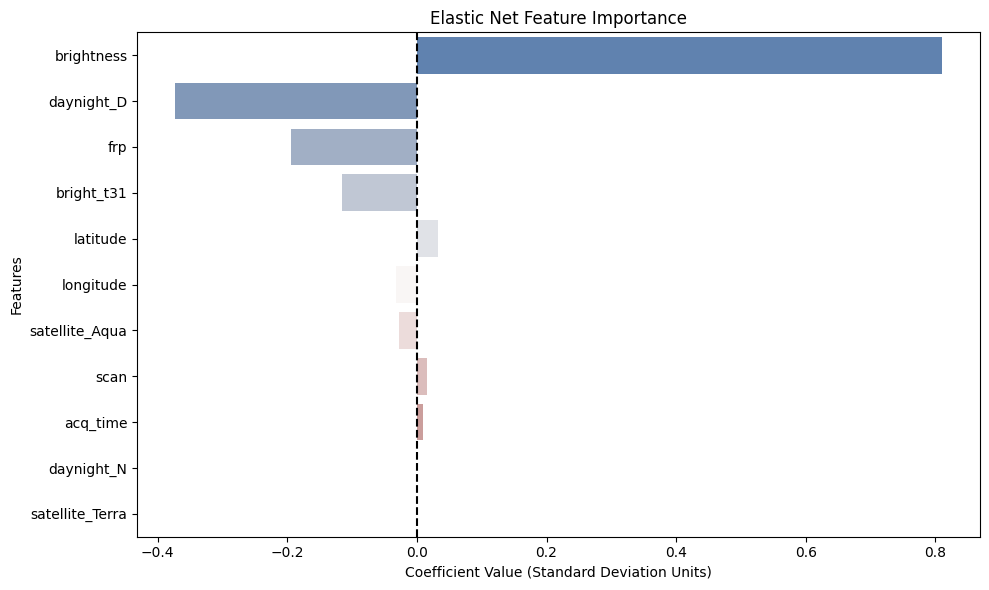

In [ ]:
# Map each feature to its elastic-net coefficient to see which the penalty shrank
importance_elastic_net = pd.DataFrame({
    "Feature": predictors_train_elastic_net.columns,
    "Coefficient": model_elastic_net.coef_
})
importance_elastic_net["Abs_Coefficient"] = importance_elastic_net["Coefficient"].abs()
importance_elastic_net = importance_elastic_net.sort_values(by="Abs_Coefficient", ascending=False).drop(columns=["Abs_Coefficient"])

# Print the results
display(HTML("<h2>Standardized Feature Importance Elastic Net</h2>"))
print(importance_elastic_net)

# Plot the coefficients (features driven to ~0 were shrunk out by the L1 penalty)
matplt.figure(figsize=(10, 6))
sea.barplot(x="Coefficient", y="Feature", data=importance_elastic_net, palette="vlag")
matplt.axvline(x=0, color="black", linestyle="--")
matplt.title("Elastic Net Feature Importance")
matplt.xlabel("Coefficient Value (Standard Deviation Units)")
matplt.ylabel("Features")
matplt.tight_layout()
matplt.show()

<h3>Experiment: GLMs with Appropriate Target Distributions</h3>

A generalized linear model (GLM) pairs a linear predictor with a probability distribution and a link function chosen to match the response. Two responses are modeled here, each with the distribution that fits its shape:

Binary response confidence_category_high Binomial family with a logit link (the GLM form of logistic regression), reported with likelihood diagnostics (AIC, deviance).

Continuous response confidence (a percentage bounded on [0, 100]) comparing a
naive Gaussian GLM against a Binomial GLM fit to the proportion confidence/100, which respects the bounded, skewed nature of percentage data.


In [ ]:
# ---- GLM 1: Binomial family (logit link) for the BINARY response ----
# Copy the data into dataframes specific to this model (binary categorical response)
predictors_train_glm_binomial = predictors_train_categorical_global
response_train_glm_binomial = response_train_categorical_global
predictors_validation_glm_binomial = predictors_validation_categorical_global
response_validation_glm_binomial = response_validation_categorical_global

# statsmodels needs numeric predictors and an explicit intercept. The one-hot pairs
# (satellite_Aqua/Terra and daynight_D/N) are perfectly complementary, so we drop one of
# each pair to avoid the dummy-variable trap (a singular matrix), then add a constant.
def build_design_matrix_glm(predictor_frame_glm):
    predictor_frame_glm = predictor_frame_glm.drop(columns=['satellite_Terra', 'daynight_N'])
    predictor_frame_glm = predictor_frame_glm.astype(float)
    return sm.add_constant(predictor_frame_glm, has_constant='add')

# Build the design matrices for train and validation
design_train_glm_binomial = build_design_matrix_glm(predictors_train_glm_binomial)
design_validation_glm_binomial = build_design_matrix_glm(predictors_validation_glm_binomial)

# Cast the True/False response to integers 0/1 for the Binomial family
response_train_glm_binomial = response_train_glm_binomial.astype(int)
response_validation_glm_binomial = response_validation_glm_binomial.astype(int)

# Record the time, this will be when the model starts training
start_time_glm_binomial = time.time()

# Run the model (Binomial family uses the logit link by default)
model_glm_binomial = sm.GLM(
    response_train_glm_binomial,
    design_train_glm_binomial,
    family=sm.families.Binomial()
).fit()

# Record the time, this will be when the model stops training
end_time_glm_binomial = time.time()

# Calculate total elapsed time
total_time_glm_binomial = round(end_time_glm_binomial - start_time_glm_binomial, 2)

# Predicted probabilities and 0.5-threshold class predictions on the validation set
probabilities_glm_binomial = model_glm_binomial.predict(design_validation_glm_binomial)
predictions_glm_binomial = (probabilities_glm_binomial >= 0.5).astype(int)

# Calculate metrics
roc_auc_glm_binomial = round(roc_auc_score(response_validation_glm_binomial, probabilities_glm_binomial) * 100, 2)
accuracy_glm_binomial = round(accuracy_score(response_validation_glm_binomial, predictions_glm_binomial) * 100, 2)
log_loss_glm_binomial = round(log_loss(response_validation_glm_binomial, probabilities_glm_binomial), 5)
aic_glm_binomial = round(model_glm_binomial.aic, 2)
null_deviance_glm_binomial = round(model_glm_binomial.null_deviance, 2)
residual_deviance_glm_binomial = round(model_glm_binomial.deviance, 2)

# Create a confusion matrix and get the values
true_negatives_glm_binomial, false_positives_glm_binomial, false_negatives_glm_binomial, true_positives_glm_binomial = confusion_matrix(response_validation_glm_binomial, predictions_glm_binomial).ravel()

# Initiate a console
console_confusion_matrix_glm_binomial = Console()

# Create a table to display the confusion matrix
table_confusion_matrix_glm_binomial = Table(title="[bold]Confusion Matrix Binomial GLM[/bold]")
table_confusion_matrix_glm_binomial.add_column("Classification", justify="left")
table_confusion_matrix_glm_binomial.add_column("Count", justify="right")
table_confusion_matrix_glm_binomial.add_row("True Positives", str(true_positives_glm_binomial))
table_confusion_matrix_glm_binomial.add_row("False Positives", str(false_positives_glm_binomial))
table_confusion_matrix_glm_binomial.add_row("True Negatives", str(true_negatives_glm_binomial))
table_confusion_matrix_glm_binomial.add_row("False Negatives", str(false_negatives_glm_binomial))
console_confusion_matrix_glm_binomial.print(table_confusion_matrix_glm_binomial)

# Initiate a console
console_glm_binomial_report = Console()

# Create a table with classification metrics PLUS the GLM-specific likelihood diagnostics
table_glm_binomial_report = Table(title="[bold]Binomial GLM Model Report[/bold]")
table_glm_binomial_report.add_column("Metric", justify="left")
table_glm_binomial_report.add_column("Value", justify="right")
table_glm_binomial_report.add_row("Training Time", f"{total_time_glm_binomial} s")
table_glm_binomial_report.add_row("Accuracy", f"{accuracy_glm_binomial} %")
table_glm_binomial_report.add_row("ROC-AUC Score", f"{roc_auc_glm_binomial} %")
table_glm_binomial_report.add_row("Log Loss", f"{log_loss_glm_binomial}")
table_glm_binomial_report.add_row("AIC", f"{aic_glm_binomial}")
table_glm_binomial_report.add_row("Null Deviance", f"{null_deviance_glm_binomial}")
table_glm_binomial_report.add_row("Residual Deviance", f"{residual_deviance_glm_binomial}")
console_glm_binomial_report.print(table_glm_binomial_report)

 Confusion Matrix Binomial 
            GLM            
┏━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Classification  ┃ Count ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ True Positives  │ 24523 │
│ False Positives │  4086 │
│ True Negatives  │  5599 │
│ False Negatives │  2511 │
└─────────────────┴───────┘

    Binomial GLM Model Report    
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Metric            ┃     Value ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ Training Time     │    1.04 s │
│ Accuracy          │   82.03 % │
│ ROC-AUC Score     │    87.7 % │
│ Log Loss          │   0.38849 │
│ AIC               │  84269.22 │
│ Null Deviance     │ 127132.18 │
│ Residual Deviance │  84249.22 │
└───────────────────┴───────────┘

In [ ]:
# ---- GLM 2: choosing an APPROPRIATE target distribution for the continuous response ----
# 'confidence' is a percentage bounded on [0, 100] (left-skewed, mean ~75). A Gaussian GLM
# assumes an unbounded, symmetric response and can predict impossible values outside [0, 100].
# Modeling the response as a PROPORTION p = confidence/100 with a Binomial family (logit link)
# respects the bound and the mean-variance shape of percentage data -> a more appropriate fit.

# Reload the ORIGINAL (un-scaled) confidence on its natural 0-100 scale and align by row index
confidence_raw_all_glm = pd.read_csv('fire_nrt_M6_96619.csv')['confidence']
response_train_glm_raw = confidence_raw_all_glm.loc[predictors_train_continuous_global.index].astype(float)
response_validation_glm_raw = confidence_raw_all_glm.loc[predictors_validation_continuous_global.index].astype(float)

# Reuse the same design-matrix helper (intercept added, dummy-variable trap handled)
design_train_glm_continuous = build_design_matrix_glm(predictors_train_continuous_global)
design_validation_glm_continuous = build_design_matrix_glm(predictors_validation_continuous_global)

# (a) Gaussian GLM (identity link) on raw confidence -- the naive baseline distribution
start_time_glm_gaussian = time.time()
model_glm_gaussian = sm.GLM(response_train_glm_raw, design_train_glm_continuous, family=sm.families.Gaussian()).fit()
total_time_glm_gaussian = round(time.time() - start_time_glm_gaussian, 2)
predictions_glm_gaussian = model_glm_gaussian.predict(design_validation_glm_continuous)
rmse_glm_gaussian = round(np.sqrt(mean_squared_error(response_validation_glm_raw, predictions_glm_gaussian)), 4)
r2_glm_gaussian = round(r2_score(response_validation_glm_raw, predictions_glm_gaussian), 4)

# (b) Binomial GLM (logit link) on the PROPORTION confidence/100 -- the appropriate distribution
response_train_glm_proportion = (response_train_glm_raw / 100.0).clip(1e-6, 1 - 1e-6)
start_time_glm_proportion = time.time()
model_glm_proportion = sm.GLM(response_train_glm_proportion, design_train_glm_continuous, family=sm.families.Binomial()).fit()
total_time_glm_proportion = round(time.time() - start_time_glm_proportion, 2)
# Map predicted proportion back to the 0-100 scale for an apples-to-apples comparison
predictions_glm_proportion = model_glm_proportion.predict(design_validation_glm_continuous) * 100.0
rmse_glm_proportion = round(np.sqrt(mean_squared_error(response_validation_glm_raw, predictions_glm_proportion)), 4)
r2_glm_proportion = round(r2_score(response_validation_glm_raw, predictions_glm_proportion), 4)

# Side-by-side comparison table
console_glm_distribution_report = Console()
table_glm_distribution_report = Table(title="[bold]GLM Target Distribution Comparison (continuous confidence)[/bold]")
table_glm_distribution_report.add_column("GLM Family (link)", justify="left")
table_glm_distribution_report.add_column("Validation RMSE", justify="right")
table_glm_distribution_report.add_column("Validation R squared", justify="right")
table_glm_distribution_report.add_column("Train Time", justify="right")
table_glm_distribution_report.add_row("Gaussian (identity)", f"{rmse_glm_gaussian}", f"{r2_glm_gaussian}", f"{total_time_glm_gaussian} s")
table_glm_distribution_report.add_row("Binomial (logit) on proportion", f"{rmse_glm_proportion}", f"{r2_glm_proportion}", f"{total_time_glm_proportion} s")
console_glm_distribution_report.print(table_glm_distribution_report)

               GLM Target Distribution Comparison (continuous confidence)               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ GLM Family (link)              ┃ Validation RMSE ┃ Validation R squared ┃ Train Time ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ Gaussian (identity)            │         20.4088 │               0.3305 │     0.33 s │
│ Binomial (logit) on proportion │         16.6689 │               0.5534 │     0.83 s │
└────────────────────────────────┴─────────────────┴──────────────────────┴────────────┘